# Bai 1 - FCN cho semantic segmentation

Bam Run All la notebook se chay tu dau den cuoi: doc data, show mau crop/mask, tao model, train 2 epoch, show prediction sau moi epoch, roi danh gia test.

In [34]:
# Cell 1 - Import va cau hinh chung
import csv
import random
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

BASE_DIR = Path(r"D:/DuyToan/Python/DUT_AI/day 50 8-8-2026")
DATA_ROOT = BASE_DIR / "data" / "CamVid"

IMG_SIZE = (352, 480)       # (height, width)
TRAIN_RESIZE = (384, 512)   # resize lon hon 1 chut roi crop ve IMG_SIZE
CROP_SIZE = IMG_SIZE
BATCH_SIZE = 2
NUM_WORKERS = 0             # Windows de 0 cho on dinh khi chay notebook
IGNORE_INDEX = 255
LR = 1e-4
EPOCHS =20                   # Run All se train 2 epoch
SHOW_COUNT = 2              # So anh show sau moi epoch

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
VOID_NAMES = {"void", "unlabelled", "unlabeled", "unknown"}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)
print("Data root:", DATA_ROOT)

Device: cuda
Data root: D:\DuyToan\Python\DUT_AI\day 50 8-8-2026\data\CamVid


In [35]:
# Cell 2 - Lay data ve neu chua co
# Dataset dung ban public nay:
# https://github.com/stonewst/CamVid-for-Segmentation
# Layout:
# data/CamVid/class_palette.csv
# data/CamVid/train, trainannot, val, valannot, test, testannot

if not (DATA_ROOT / "class_palette.csv").exists():
    DATA_ROOT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.check_call([
        "git", "clone", "--depth", "1",
        "https://github.com/stonewst/CamVid-for-Segmentation.git",
        str(DATA_ROOT),
    ])

print("DATA_ROOT ton tai:", DATA_ROOT.exists())
print("palette ton tai:", (DATA_ROOT / "class_palette.csv").exists())
print("train ton tai:", (DATA_ROOT / "train").exists())
print("trainannot ton tai:", (DATA_ROOT / "trainannot").exists())

DATA_ROOT ton tai: True
palette ton tai: True
train ton tai: True
trainannot ton tai: True


In [36]:
# Cell 3 - Doc bang mau class_palette.csv
# Mask cua CamVid la anh RGB. Moi mau RGB tuong ung voi 1 class.
# Ta doi tung mau RGB thanh class_id de tinh CrossEntropyLoss.

class_names = []
color_to_id = {}
id_to_color = []

with open(DATA_ROOT / "class_palette.csv", newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        name = row["name"].strip()
        color = (int(row["r"]), int(row["g"]), int(row["b"]))

        if name.lower() in VOID_NAMES:
            color_to_id[color] = IGNORE_INDEX
        else:
            class_id = len(class_names)
            class_names.append(name)
            color_to_id[color] = class_id
            id_to_color.append(color)

NUM_CLASSES = len(class_names)
print("So class:", NUM_CLASSES)
print("Class:", class_names)

So class: 11
Class: ['Sky', 'Building', 'Pole', 'Road', 'Sidewalk', 'Tree', 'SignSymbol', 'Fence', 'Car', 'Pedestrian', 'Bicyclist']


In [37]:
# Cell 4 - Ham doi mask va transform anh/mask
def doi_mask_mau_sang_mask_class(mask_rgb):
    mask_np = np.array(mask_rgb.convert("RGB"), dtype=np.uint8)
    mask_id = np.full(mask_np.shape[:2], IGNORE_INDEX, dtype=np.int64)

    for color, class_id in color_to_id.items():
        vung_mau = np.all(mask_np == np.array(color, dtype=np.uint8), axis=-1)
        mask_id[vung_mau] = class_id

    return torch.from_numpy(mask_id).long()


def bien_doi_anh_va_mask(image, mask, train=True):
    # Segmentation bat buoc image va mask phai crop/flip giong nhau.
    # Image dung BILINEAR cho muot, mask dung NEAREST de khong bi sinh mau/class la.
    if train:
        image = TF.resize(image, TRAIN_RESIZE, interpolation=InterpolationMode.BILINEAR)
        mask = TF.resize(mask, TRAIN_RESIZE, interpolation=InterpolationMode.NEAREST)

        i, j, h, w = T.RandomCrop.get_params(image, output_size=CROP_SIZE)
        image = TF.crop(image, i, j, h, w)
        mask = TF.crop(mask, i, j, h, w)

        if random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)
    else:
        image = TF.resize(image, IMG_SIZE, interpolation=InterpolationMode.BILINEAR)
        mask = TF.resize(mask, IMG_SIZE, interpolation=InterpolationMode.NEAREST)

    image = TF.to_tensor(image)
    image = TF.normalize(image, mean=IMAGENET_MEAN, std=IMAGENET_STD)
    return image, mask

In [38]:
# Cell 5 - Dataset class
class CamVidDataset(Dataset):
    """Doc cap anh goc va mask nhan."""
    def __init__(self, root, split="train", train=True):
        self.root = Path(root)
        self.split = split
        self.train = train

        self.image_dir = self.root / split
        self.mask_dir = self.root / f"{split}annot"
        self.image_paths = sorted(list(self.image_dir.glob("*.png")) + list(self.image_dir.glob("*.jpg")))
        self.mask_paths = sorted(list(self.mask_dir.glob("*.png")) + list(self.mask_dir.glob("*.jpg")))

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert("RGB")
        mask_rgb = Image.open(self.mask_paths[idx]).convert("RGB")

        image, mask_rgb = bien_doi_anh_va_mask(image, mask_rgb, train=self.train)
        mask = doi_mask_mau_sang_mask_class(mask_rgb)
        return image, mask

In [39]:
# Cell 6 - Tao Dataset va DataLoader
train_ds = CamVidDataset(DATA_ROOT, "train", train=True)
val_ds = CamVidDataset(DATA_ROOT, "val", train=False)
test_ds = CamVidDataset(DATA_ROOT, "test", train=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print("So anh train/val/test:", len(train_ds), len(val_ds), len(test_ds))
print("So batch train/val/test:", len(train_loader), len(val_loader), len(test_loader))

So anh train/val/test: 367 101 233
So batch train/val/test: 184 51 117


In [40]:
# Cell 7 - Ham show anh de xem crop/mask va prediction
def anh_ve_rgb(image_tensor):
    image = image_tensor.detach().cpu().clone()
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    image = image * std + mean
    image = image.clamp(0, 1)
    return image.permute(1, 2, 0).numpy()


def mask_ve_rgb(mask):
    if torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    h, w = mask.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for class_id, color in enumerate(id_to_color):
        rgb[mask == class_id] = np.array(color, dtype=np.uint8)
    return rgb


def show_data_da_crop(dataset, count=3):
    # Goi dataset train nhieu lan se thay random crop/random flip khac nhau.
    fig, axes = plt.subplots(count, 2, figsize=(8, 3.5 * count))
    if count == 1:
        axes = np.array([axes])

    for i in range(count):
        image, mask = dataset[i]
        axes[i, 0].imshow(anh_ve_rgb(image))
        axes[i, 0].set_title("Anh sau resize/crop/flip")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask_ve_rgb(mask))
        axes[i, 1].set_title("Mask sau resize/crop/flip")
        axes[i, 1].axis("off")

    plt.tight_layout()
    display(fig)
    plt.close(fig)


@torch.no_grad()
def du_doan_1_anh(model, image):
    model.eval()
    logits = model(image.unsqueeze(0).to(DEVICE))
    pred = torch.argmax(logits, dim=1)[0]
    return pred.cpu()


@torch.no_grad()
def show_prediction(model, loader, title, count=2):
    model = model.to(DEVICE).eval()
    images, masks = next(iter(loader))
    count = min(count, images.size(0))

    fig, axes = plt.subplots(count, 3, figsize=(11, 3.5 * count))
    if count == 1:
        axes = np.array([axes])

    for i in range(count):
        image = images[i]
        mask = masks[i]
        pred = du_doan_1_anh(model, image)

        axes[i, 0].imshow(anh_ve_rgb(image))
        axes[i, 0].set_title("Anh goc")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask_ve_rgb(mask))
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(mask_ve_rgb(pred))
        axes[i, 2].set_title(title)
        axes[i, 2].axis("off")

    plt.tight_layout()
    display(fig)
    plt.close(fig)

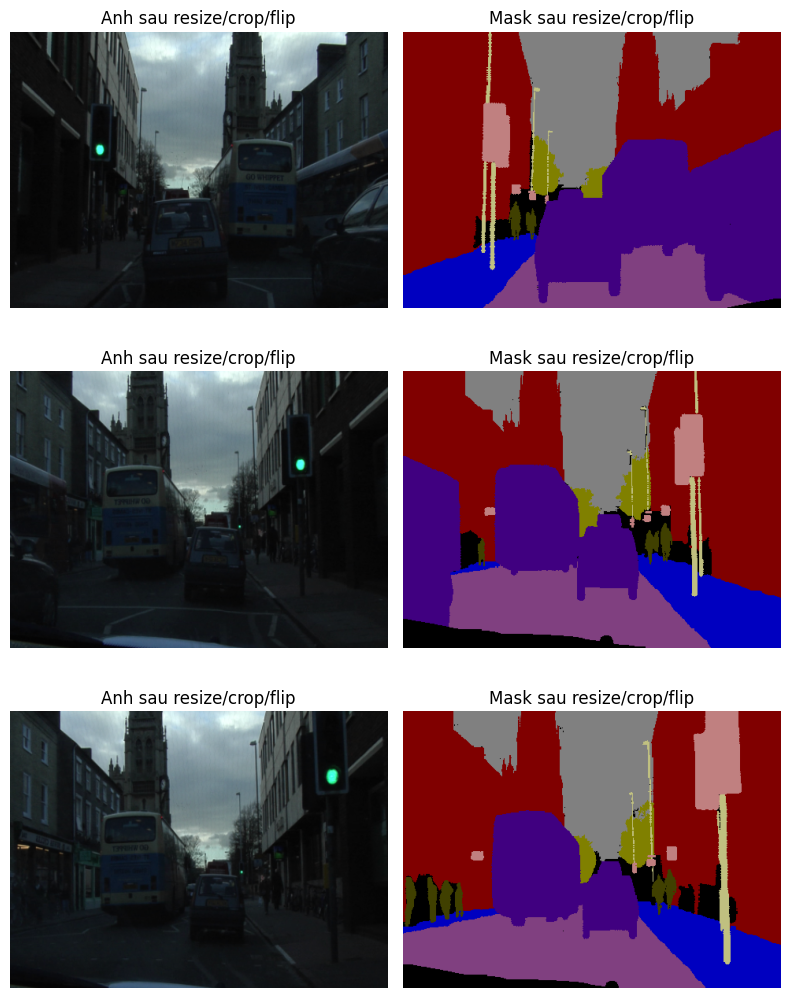

In [41]:
# Cell 8 - Show data sau khi crop/flip de xem pipeline lam gi
show_data_da_crop(train_ds, count=3)

In [42]:
# Cell 9 - Cac ham CNN nho ben trong FCN
def lay_vgg16_backbone(pretrained=False):
    weights = models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None
    vgg = models.vgg16(weights=weights).features

    pool3 = vgg[:17]       # stride 8,  kenh 256
    pool4 = vgg[17:24]     # stride 16, kenh 512
    pool5 = vgg[24:31]     # stride 32, kenh 512
    return pool3, pool4, pool5


def conv_1x1_score(in_channels, num_classes):
    # Conv 1x1 doi so kenh feature map thanh so class.
    layer = nn.Conv2d(in_channels, num_classes, kernel_size=1)
    nn.init.normal_(layer.weight, mean=0.0, std=0.01)
    nn.init.constant_(layer.bias, 0.0)
    return layer


def khoi_tao_upsample_bilinear(layer):
    # Khoi tao ConvTranspose2d giong noi suy bilinear de upsample muot hon luc dau.
    k = layer.kernel_size[0]
    factor = (k + 1) // 2
    center = factor - 1 if k % 2 == 1 else factor - 0.5
    og = np.ogrid[:k, :k]
    filt = (1 - abs(og[0] - center) / factor) * (1 - abs(og[1] - center) / factor)

    weight = np.zeros(layer.weight.shape, dtype=np.float32)
    for c in range(layer.in_channels):
        weight[c, c, :, :] = filt
    layer.weight.data.copy_(torch.from_numpy(weight))


def upsample_layer(num_classes, kernel_size, stride, padding):
    layer = nn.ConvTranspose2d(num_classes, num_classes, kernel_size, stride, padding, bias=False)
    khoi_tao_upsample_bilinear(layer)
    return layer


def chinh_ve_dung_size(x, size):
    return F.interpolate(x, size=size, mode="bilinear", align_corners=False)

In [43]:
# Cell 10 - Model FCN-32s va FCN-8s
class FCN32s(nn.Module):
    """FCN-32s: lay pool5 roi phong to truc tiep 32 lan."""
    def __init__(self, num_classes, pretrained_backbone=False):
        super().__init__()
        self.pool3, self.pool4, self.pool5 = lay_vgg16_backbone(pretrained_backbone)
        self.score_pool5 = conv_1x1_score(512, num_classes)
        self.up32 = upsample_layer(num_classes, kernel_size=64, stride=32, padding=16)

    def forward(self, x):
        input_size = x.shape[-2:]
        p3 = self.pool3(x)
        p4 = self.pool4(p3)
        p5 = self.pool5(p4)
        score = self.score_pool5(p5)
        out = self.up32(score)
        return chinh_ve_dung_size(out, input_size)


class FCN8s(nn.Module):
    """FCN-8s: cong skip connection tu pool4 va pool3 de mask sac hon."""
    def __init__(self, num_classes, pretrained_backbone=False):
        super().__init__()
        self.pool3, self.pool4, self.pool5 = lay_vgg16_backbone(pretrained_backbone)
        self.score_pool3 = conv_1x1_score(256, num_classes)
        self.score_pool4 = conv_1x1_score(512, num_classes)
        self.score_pool5 = conv_1x1_score(512, num_classes)
        self.up2_pool5 = upsample_layer(num_classes, kernel_size=4, stride=2, padding=1)
        self.up2_pool4 = upsample_layer(num_classes, kernel_size=4, stride=2, padding=1)
        self.up8 = upsample_layer(num_classes, kernel_size=16, stride=8, padding=4)

    def forward(self, x):
        input_size = x.shape[-2:]
        p3 = self.pool3(x)
        p4 = self.pool4(p3)
        p5 = self.pool5(p4)

        s5 = self.score_pool5(p5)
        s4 = self.score_pool4(p4)
        s3 = self.score_pool3(p3)

        up5 = chinh_ve_dung_size(self.up2_pool5(s5), s4.shape[-2:])
        fuse4 = up5 + s4
        up4 = chinh_ve_dung_size(self.up2_pool4(fuse4), s3.shape[-2:])
        fuse3 = up4 + s3
        out = self.up8(fuse3)
        return chinh_ve_dung_size(out, input_size)

In [44]:
# Cell 11 - Tao model va smoke test shape, chua train
model32 = FCN32s(NUM_CLASSES, pretrained_backbone=False)
model8 = FCN8s(NUM_CLASSES, pretrained_backbone=False)

x_fake = torch.randn(1, 3, IMG_SIZE[0], IMG_SIZE[1])
with torch.no_grad():
    y32 = model32(x_fake)
    y8 = model8(x_fake)

print("FCN-32s output:", y32.shape)
print("FCN-8s output:", y8.shape)

FCN-32s output: torch.Size([1, 11, 352, 480])
FCN-8s output: torch.Size([1, 11, 352, 480])


In [45]:
# Cell 12 - Metric Pixel Accuracy va mIoU
def cap_nhat_confusion_matrix(confusion, preds, masks, num_classes):
    preds = preds.detach().view(-1).cpu()
    masks = masks.detach().view(-1).cpu()

    valid = masks != IGNORE_INDEX
    preds = preds[valid]
    masks = masks[valid]

    encoded = masks * num_classes + preds
    hist = torch.bincount(encoded, minlength=num_classes * num_classes)
    confusion += hist.reshape(num_classes, num_classes)
    return confusion


def tinh_pa_miou(confusion):
    confusion = confusion.float()
    dung = torch.diag(confusion)
    tong = confusion.sum()

    pixel_acc = dung.sum() / tong.clamp(min=1.0)
    union = confusion.sum(dim=1) + confusion.sum(dim=0) - dung
    iou = dung / union.clamp(min=1.0)
    miou = iou[union > 0].mean()

    return {"pixel_acc": float(pixel_acc.item()), "miou": float(miou.item()), "class_iou": iou.numpy()}

In [46]:
# Cell 13 - Train loop va evaluate
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0

    for images, masks in loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion, num_classes):
    model.eval()
    total_loss = 0.0
    confusion = torch.zeros(num_classes, num_classes, dtype=torch.int64)

    for images, masks in loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = model(images)
        loss = criterion(logits, masks)
        preds = torch.argmax(logits, dim=1)

        total_loss += loss.item() * images.size(0)
        confusion = cap_nhat_confusion_matrix(confusion, preds, masks, num_classes)

    metrics = tinh_pa_miou(confusion)
    metrics["loss"] = total_loss / len(loader.dataset)
    return metrics


def train_model(model, model_name, train_loader, val_loader, num_classes, epochs=EPOCHS):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    history = {"train_loss": [], "val_loss": [], "val_pixel_acc": [], "val_miou": []}

    print()
    print(f"===== Train {model_name} =====")
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_metrics = evaluate(model, val_loader, criterion, num_classes)
        scheduler.step(val_metrics["miou"])

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_pixel_acc"].append(val_metrics["pixel_acc"])
        history["val_miou"].append(val_metrics["miou"])

        print(
            f"{model_name} | Epoch {epoch:02d}/{epochs} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_metrics['loss']:.4f} | "
            f"PA={val_metrics['pixel_acc']:.4f} | "
            f"mIoU={val_metrics['miou']:.4f}"
        )

        # Show prediction sau moi epoch de xem mask tien bo nhu the nao.
        show_prediction(model, val_loader, title=f"{model_name} epoch {epoch}", count=SHOW_COUNT)

    return history


===== Train FCN-32s =====
FCN-32s | Epoch 01/20 | train_loss=1.1444 | val_loss=1.0572 | PA=0.6034 | mIoU=0.1903


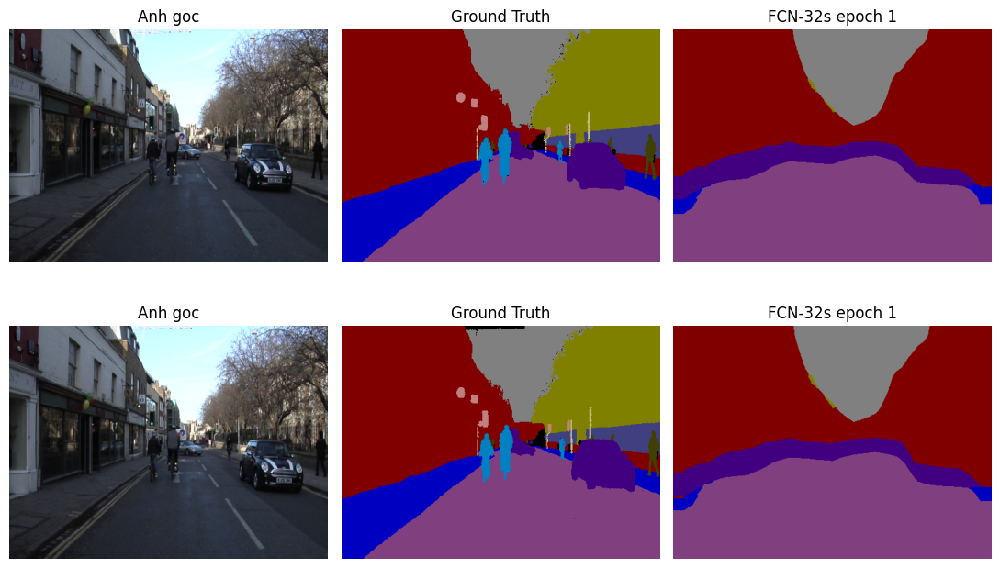

FCN-32s | Epoch 02/20 | train_loss=0.8289 | val_loss=1.0728 | PA=0.5919 | mIoU=0.1792


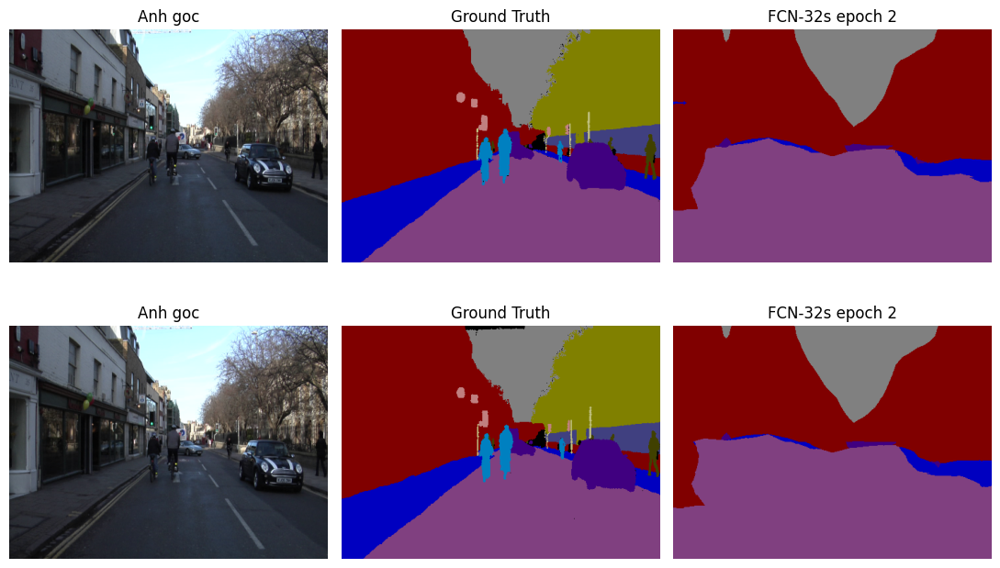

FCN-32s | Epoch 03/20 | train_loss=0.7705 | val_loss=0.9025 | PA=0.6903 | mIoU=0.2665


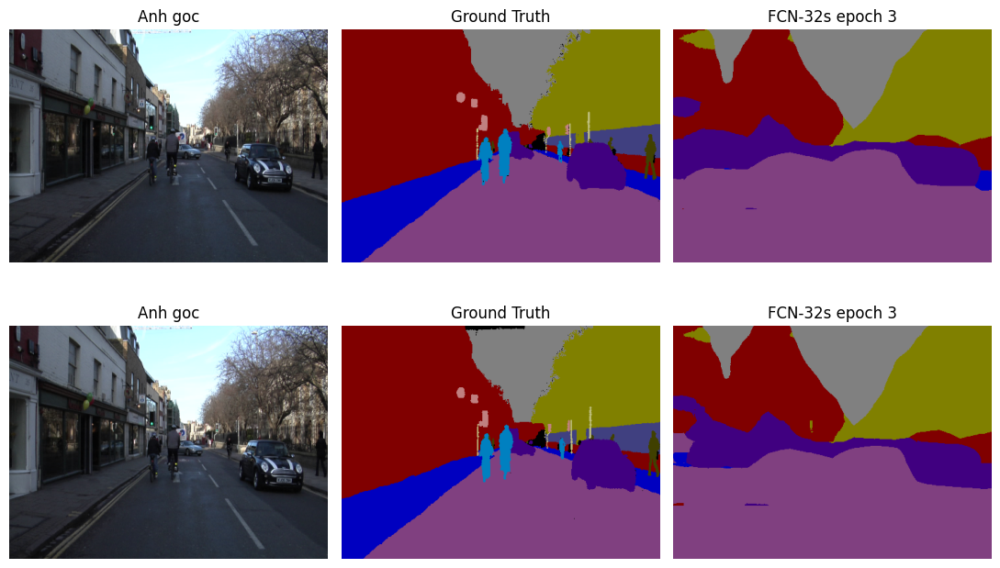

FCN-32s | Epoch 04/20 | train_loss=0.6656 | val_loss=0.6851 | PA=0.8131 | mIoU=0.3543


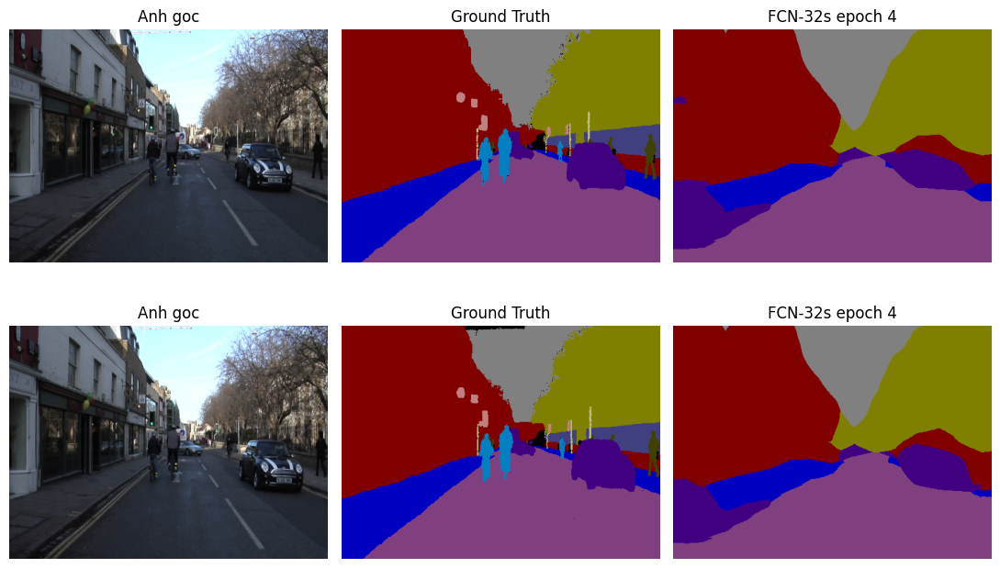

FCN-32s | Epoch 05/20 | train_loss=0.5951 | val_loss=0.7192 | PA=0.7698 | mIoU=0.3384


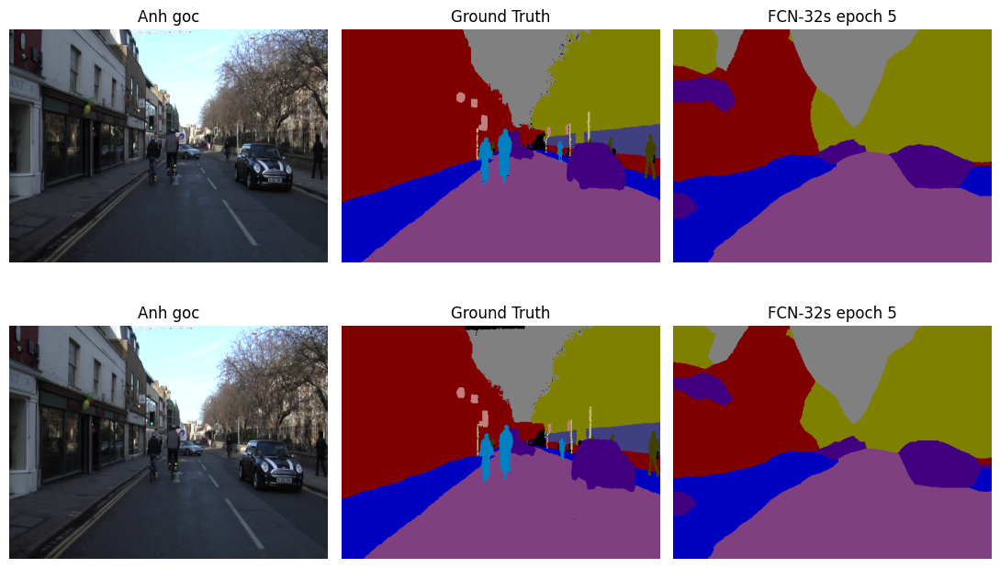

FCN-32s | Epoch 06/20 | train_loss=0.5698 | val_loss=0.5647 | PA=0.8284 | mIoU=0.3839


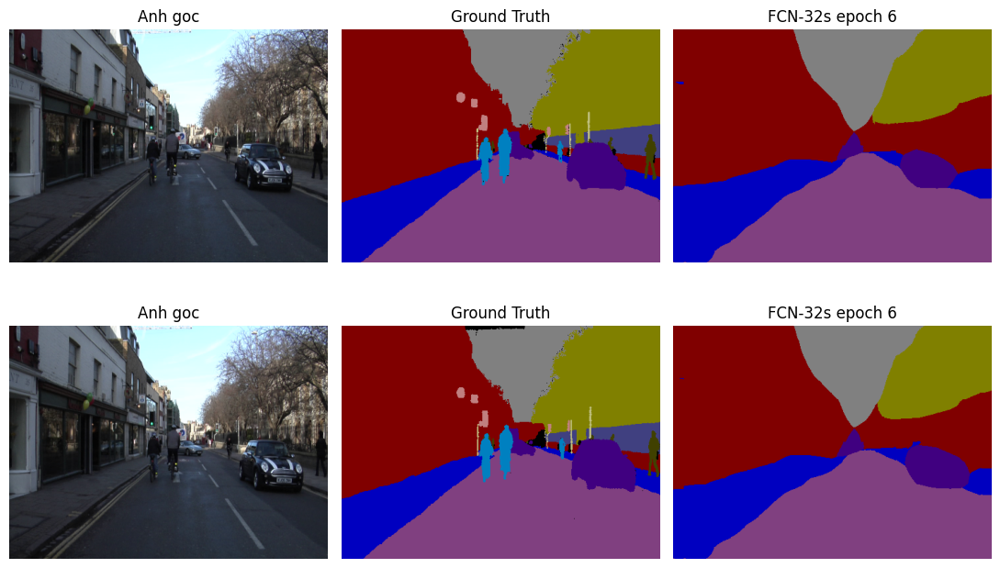

FCN-32s | Epoch 07/20 | train_loss=0.5383 | val_loss=0.5345 | PA=0.8295 | mIoU=0.3749


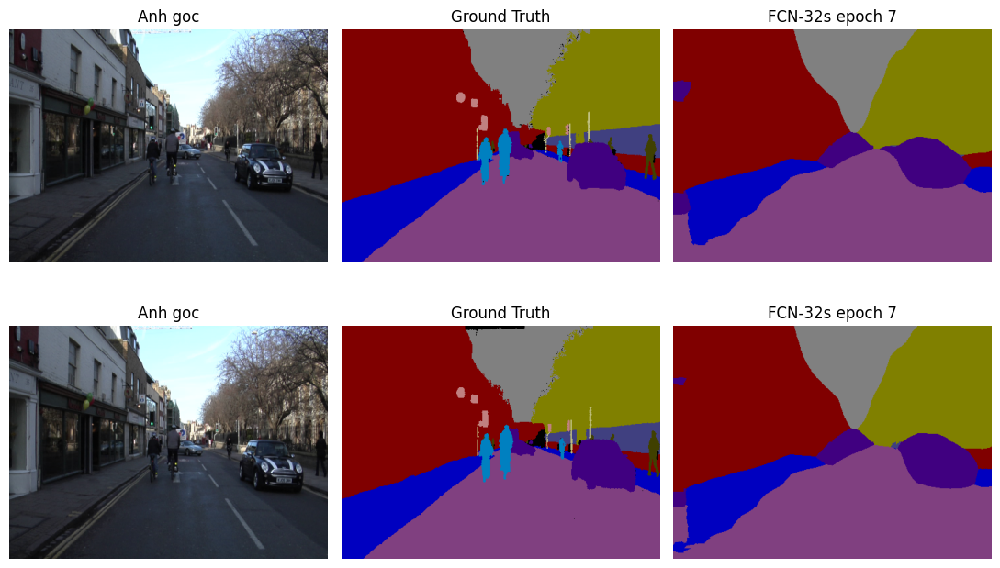

FCN-32s | Epoch 08/20 | train_loss=0.5004 | val_loss=0.4483 | PA=0.8592 | mIoU=0.4289


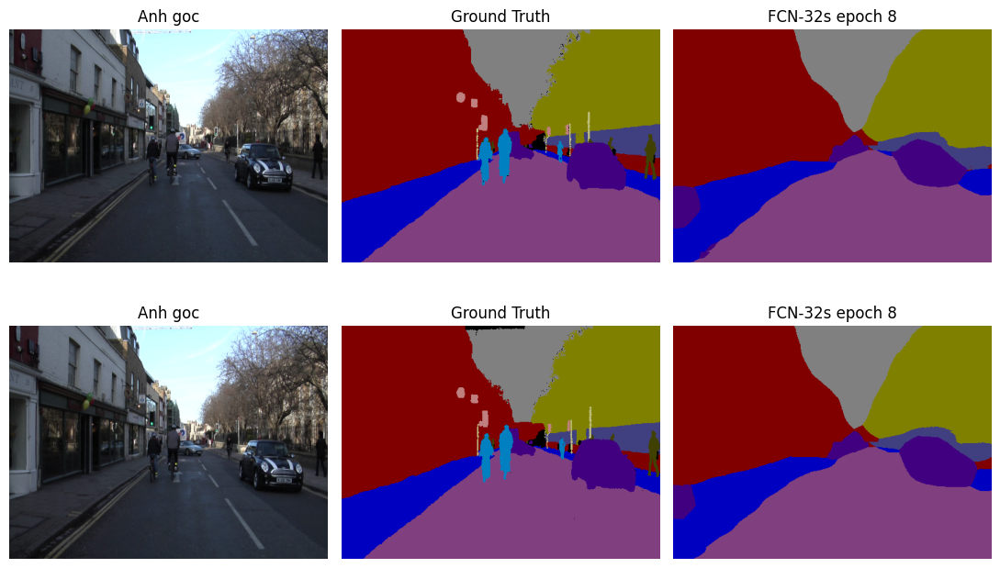

FCN-32s | Epoch 09/20 | train_loss=0.4634 | val_loss=0.4850 | PA=0.8527 | mIoU=0.4112


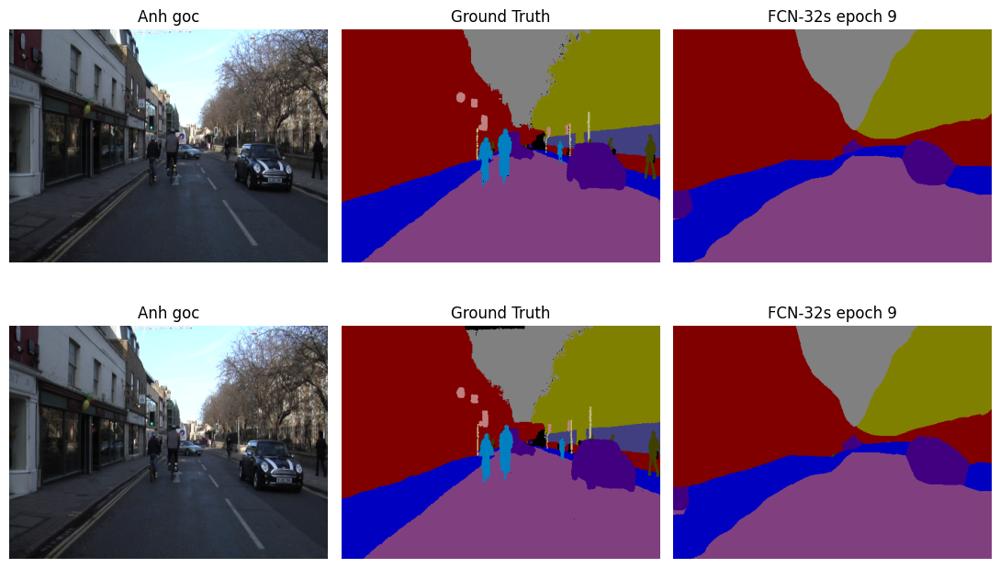

FCN-32s | Epoch 10/20 | train_loss=0.4563 | val_loss=0.4734 | PA=0.8473 | mIoU=0.3990


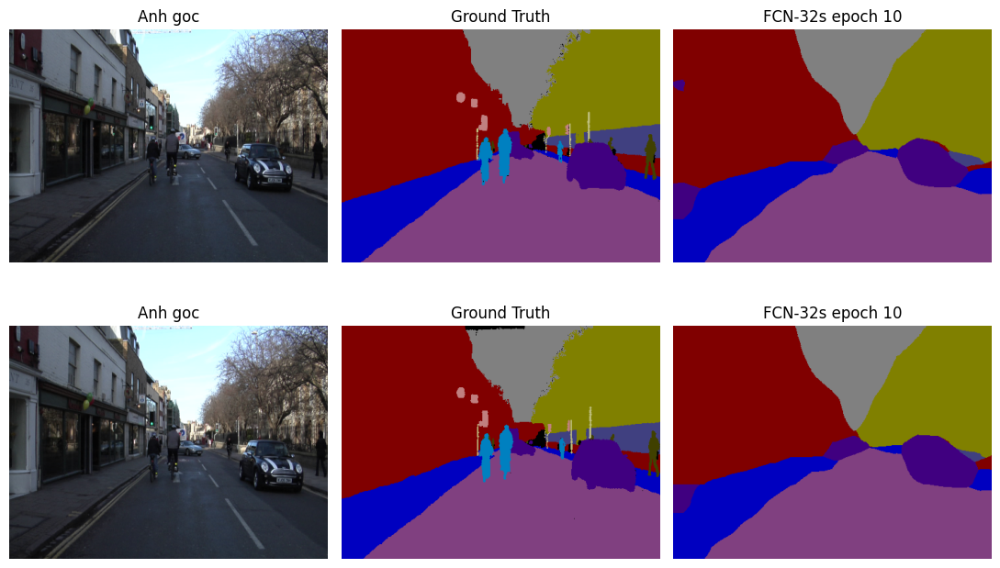

FCN-32s | Epoch 11/20 | train_loss=0.4350 | val_loss=0.4915 | PA=0.8517 | mIoU=0.3999


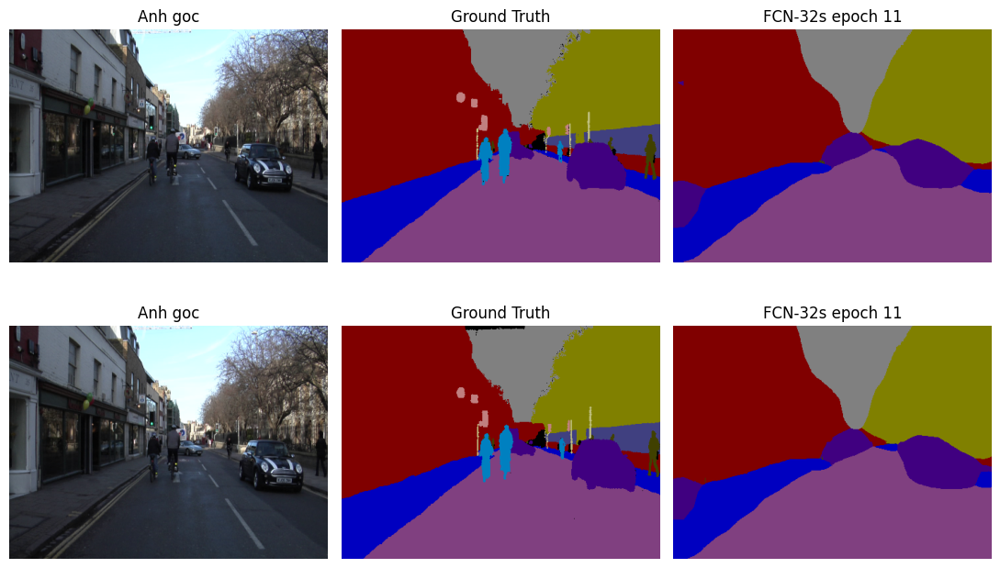

FCN-32s | Epoch 12/20 | train_loss=0.3850 | val_loss=0.3866 | PA=0.8755 | mIoU=0.4693


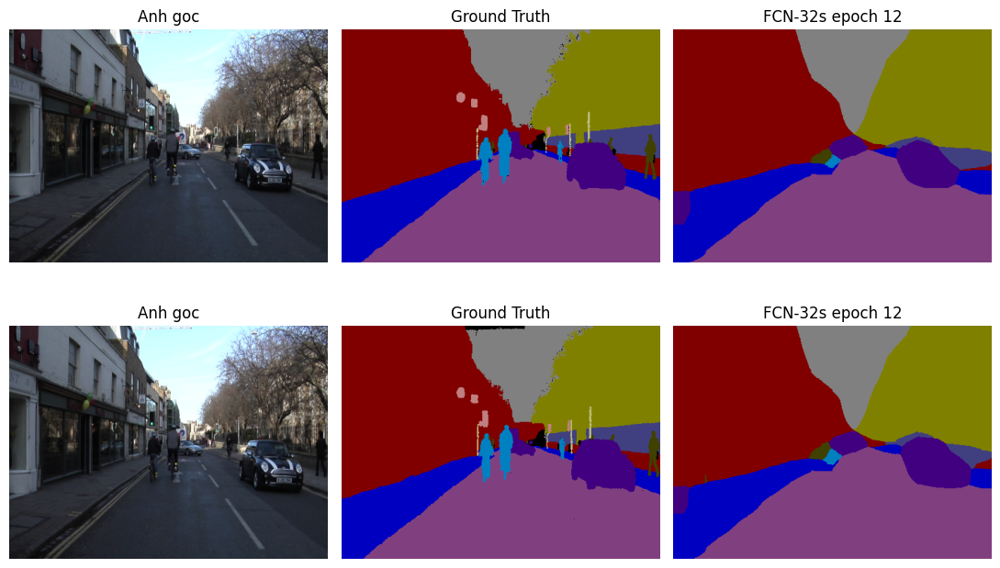

FCN-32s | Epoch 13/20 | train_loss=0.3706 | val_loss=0.3606 | PA=0.8883 | mIoU=0.5131


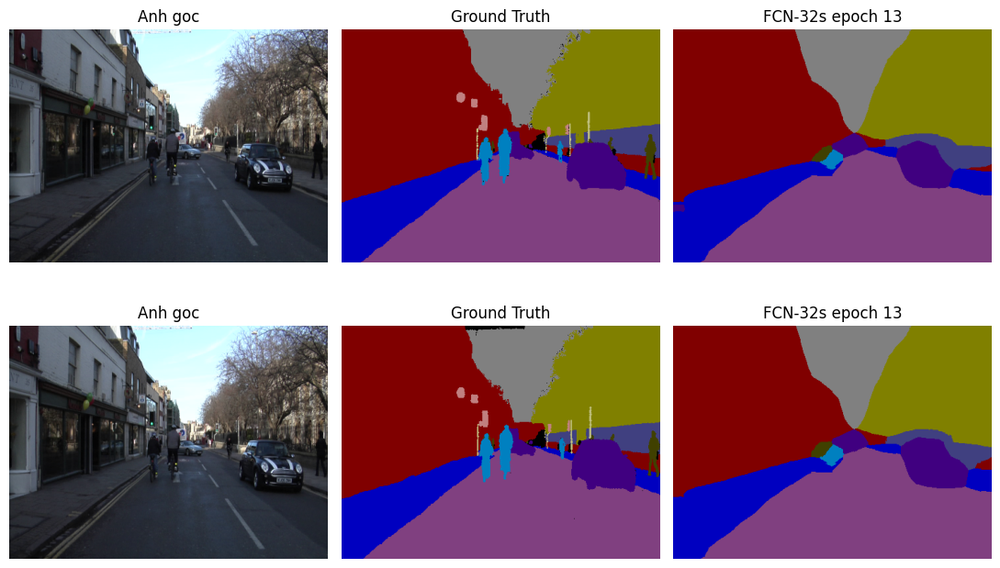

FCN-32s | Epoch 14/20 | train_loss=0.3589 | val_loss=0.3724 | PA=0.8835 | mIoU=0.4936


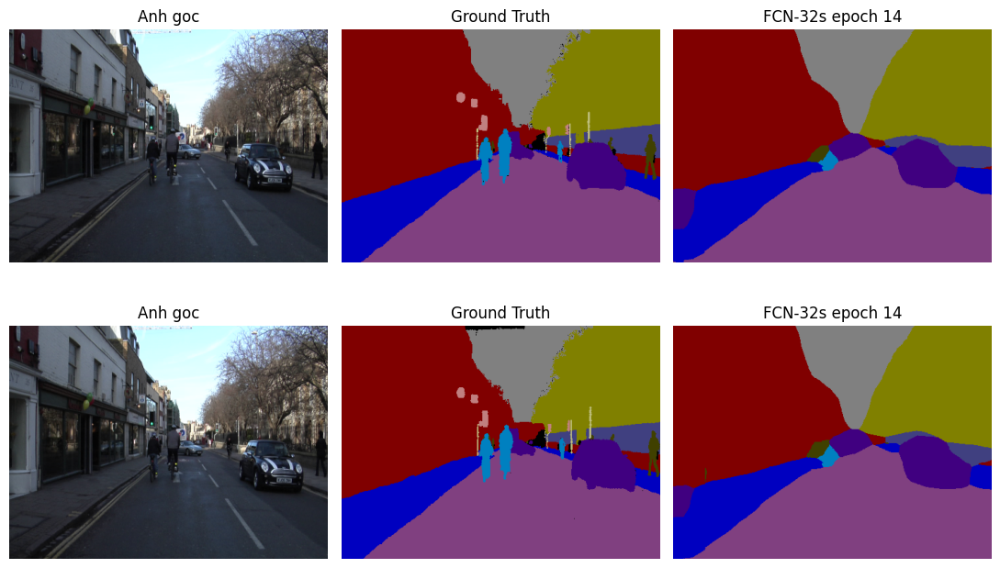

FCN-32s | Epoch 15/20 | train_loss=0.3525 | val_loss=0.3783 | PA=0.8780 | mIoU=0.4980


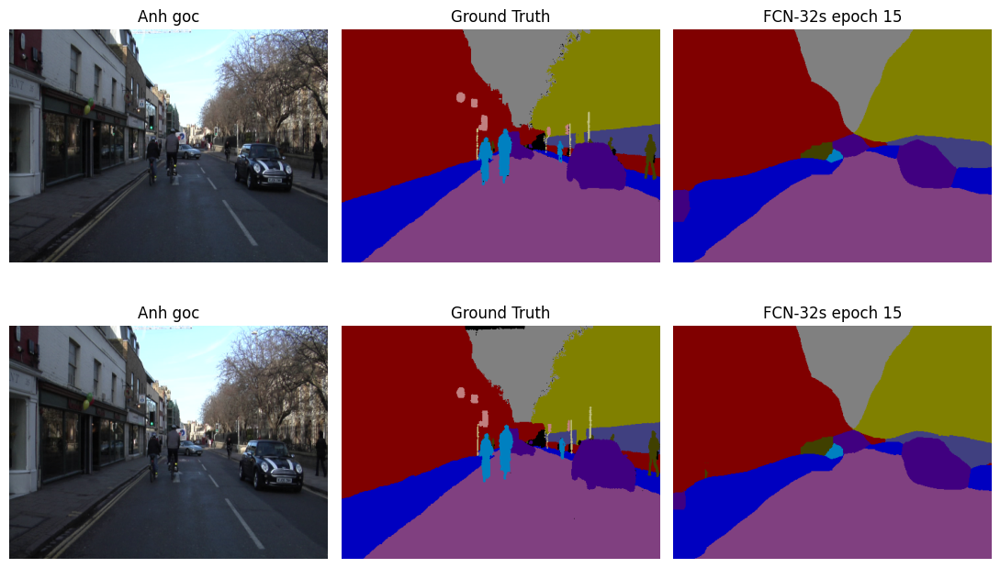

FCN-32s | Epoch 16/20 | train_loss=0.3437 | val_loss=0.3515 | PA=0.8853 | mIoU=0.5041


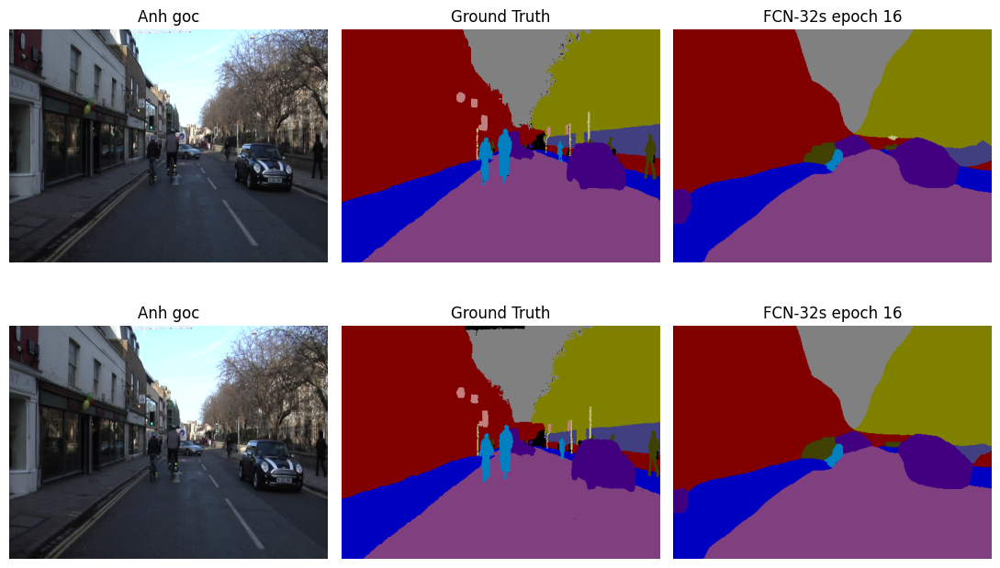

FCN-32s | Epoch 17/20 | train_loss=0.3179 | val_loss=0.3780 | PA=0.8879 | mIoU=0.5042


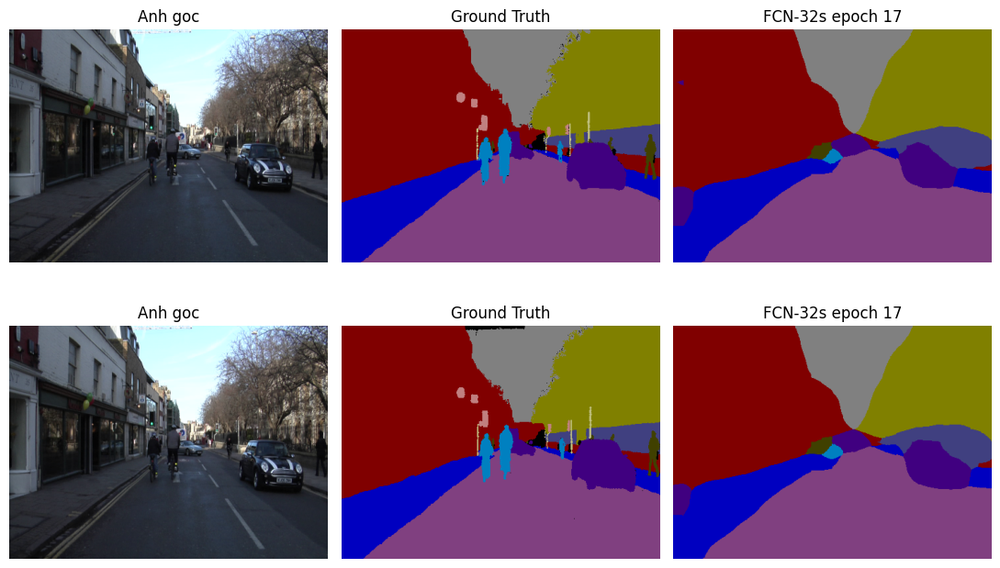

FCN-32s | Epoch 18/20 | train_loss=0.3157 | val_loss=0.3562 | PA=0.8870 | mIoU=0.5161


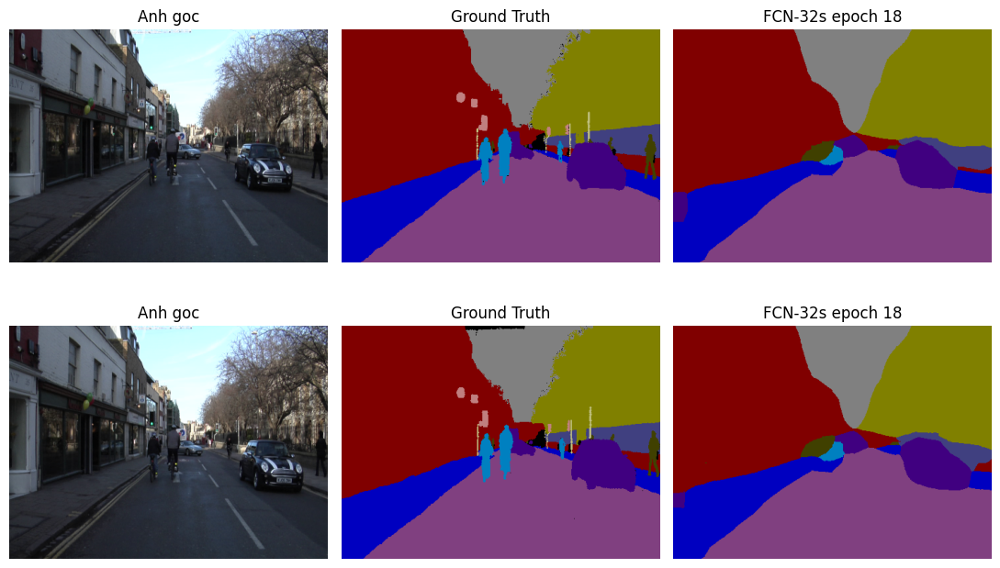

FCN-32s | Epoch 19/20 | train_loss=0.3062 | val_loss=0.3541 | PA=0.8899 | mIoU=0.5215


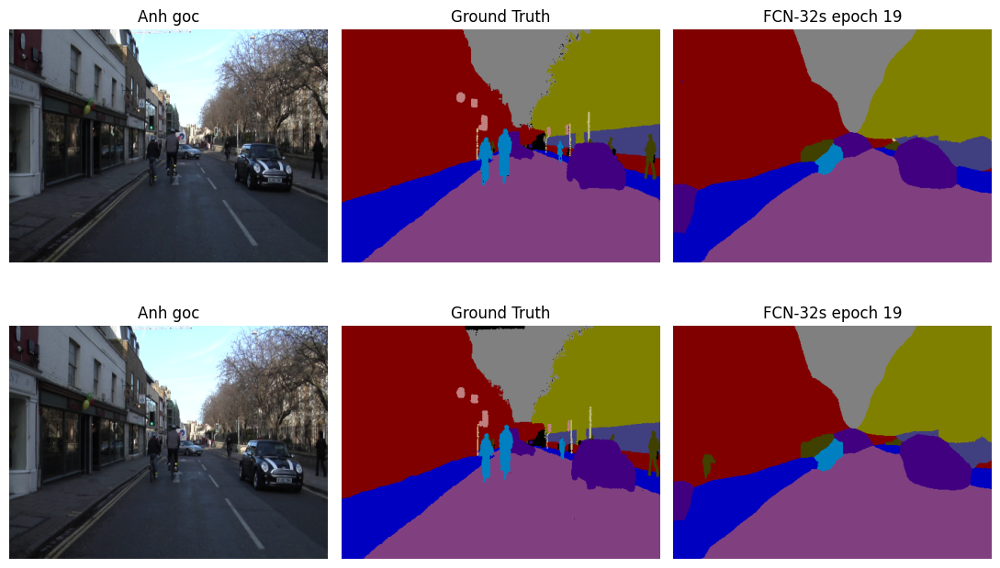

FCN-32s | Epoch 20/20 | train_loss=0.3032 | val_loss=0.3634 | PA=0.8851 | mIoU=0.5045


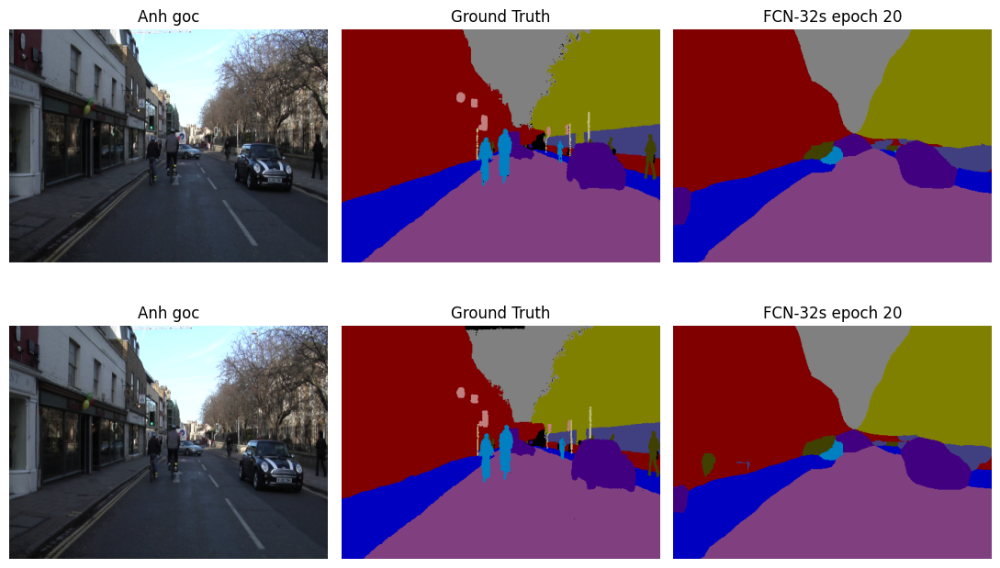


===== Train FCN-8s =====
FCN-8s | Epoch 01/20 | train_loss=1.1016 | val_loss=1.1646 | PA=0.5336 | mIoU=0.1810


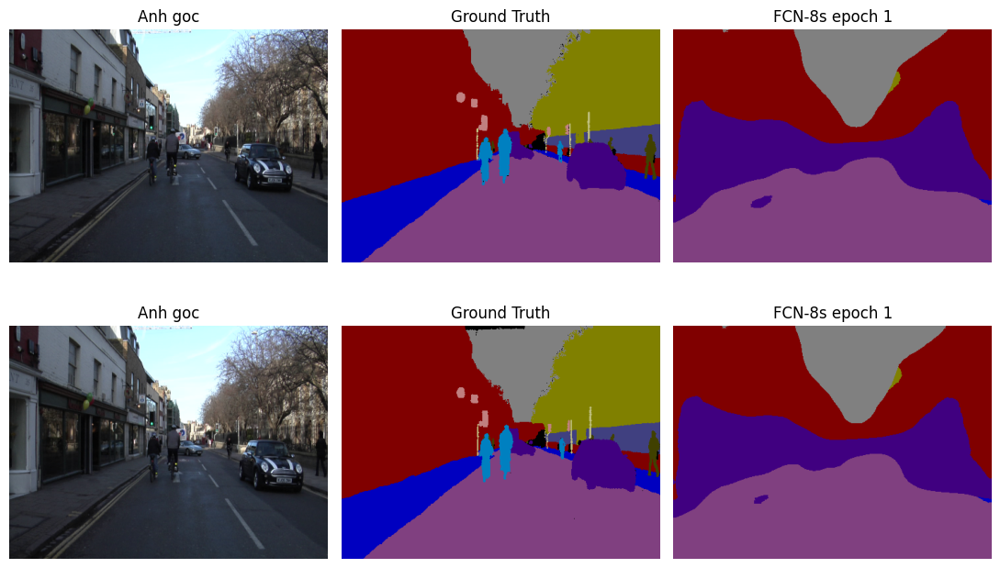

FCN-8s | Epoch 02/20 | train_loss=0.7961 | val_loss=0.8156 | PA=0.7497 | mIoU=0.3054


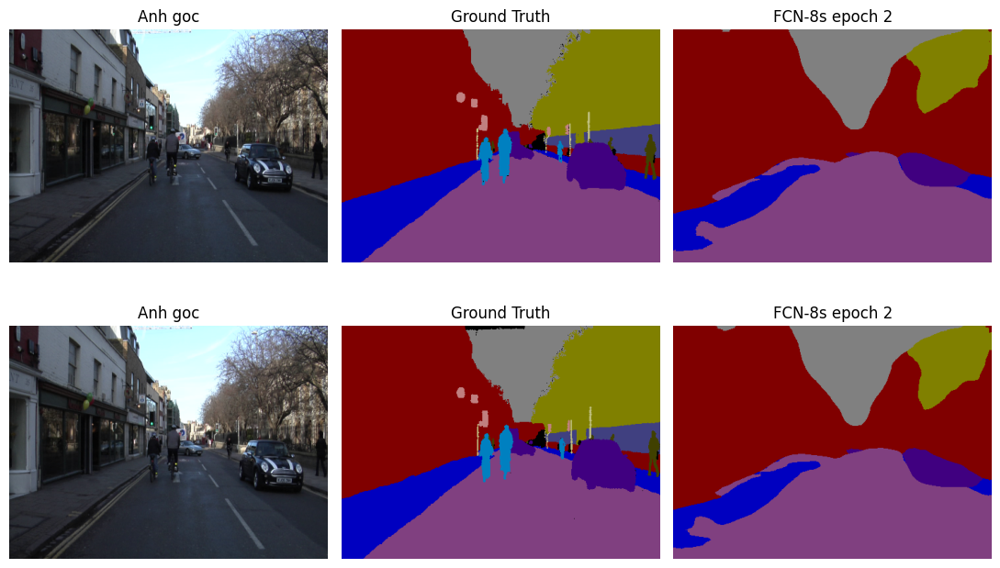

FCN-8s | Epoch 03/20 | train_loss=0.6765 | val_loss=0.7173 | PA=0.7896 | mIoU=0.3597


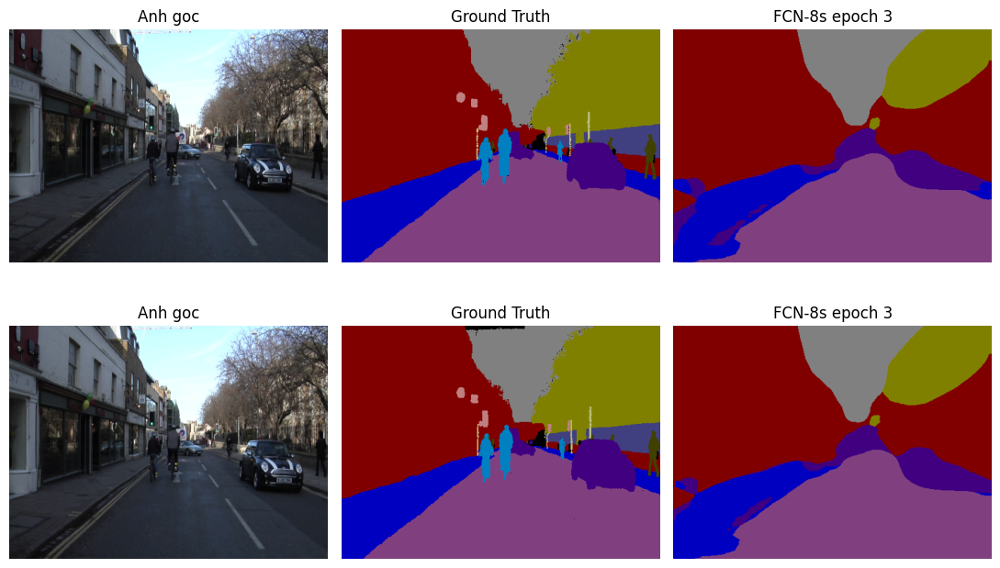

FCN-8s | Epoch 04/20 | train_loss=0.6319 | val_loss=0.6710 | PA=0.8182 | mIoU=0.3748


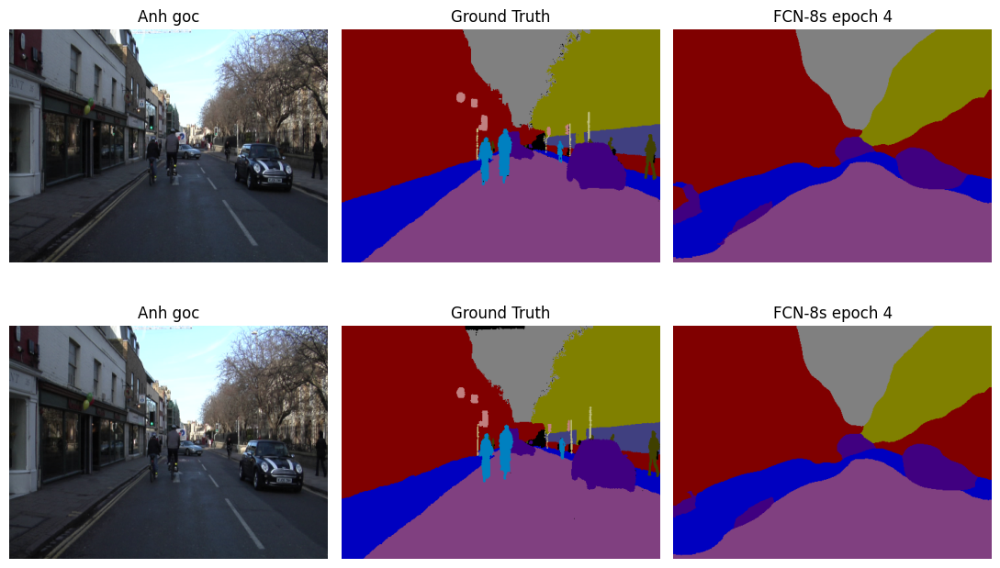

FCN-8s | Epoch 05/20 | train_loss=0.5388 | val_loss=0.6053 | PA=0.8292 | mIoU=0.3819


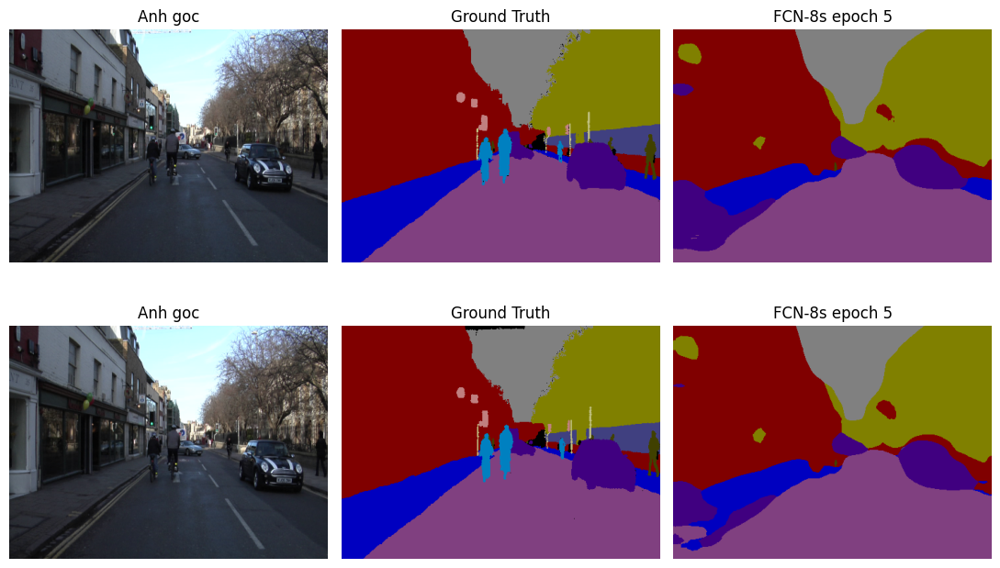

FCN-8s | Epoch 06/20 | train_loss=0.5183 | val_loss=0.5321 | PA=0.8446 | mIoU=0.3895


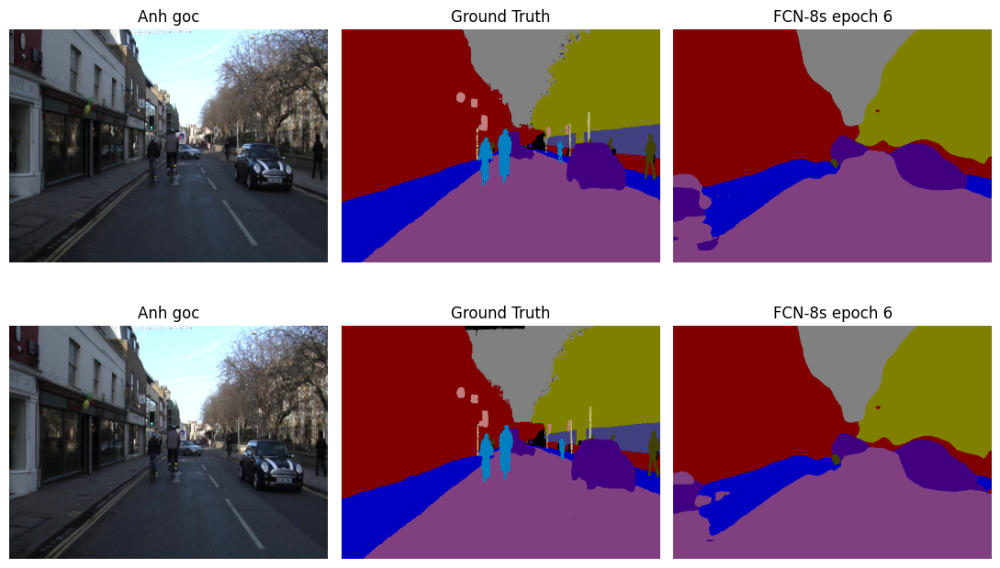

FCN-8s | Epoch 07/20 | train_loss=0.4689 | val_loss=0.4217 | PA=0.8663 | mIoU=0.4435


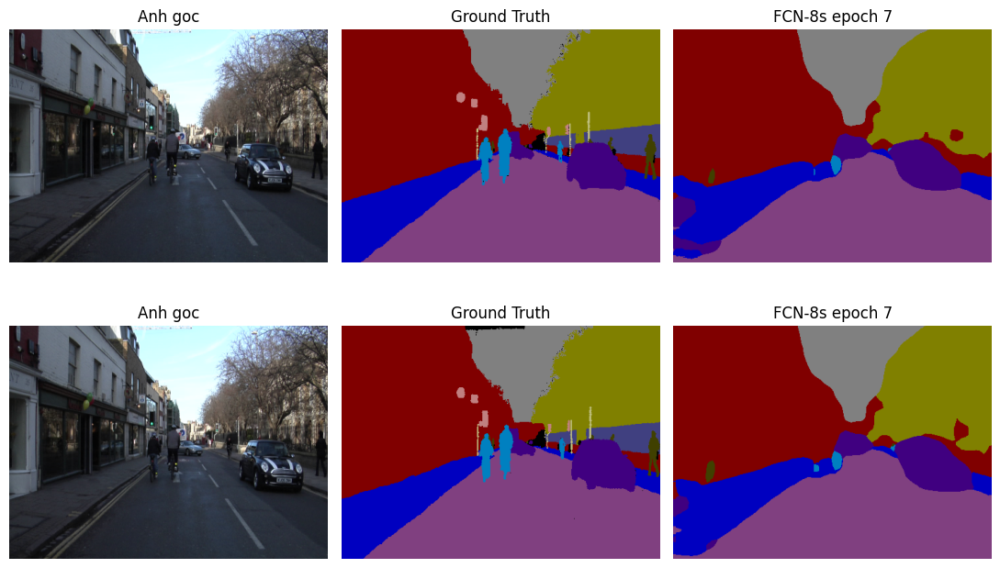

FCN-8s | Epoch 08/20 | train_loss=0.4322 | val_loss=0.4121 | PA=0.8705 | mIoU=0.4492


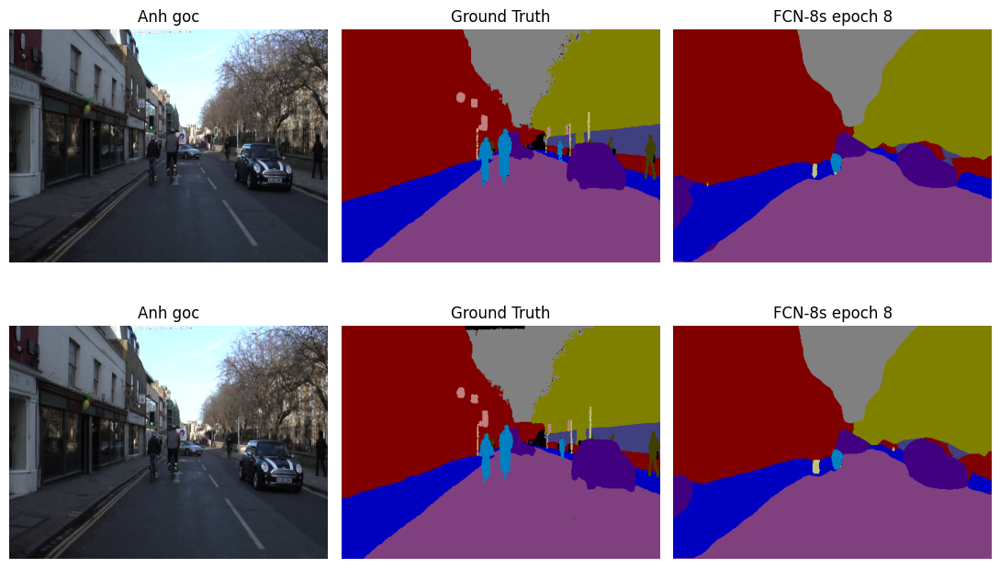

FCN-8s | Epoch 09/20 | train_loss=0.4070 | val_loss=0.4072 | PA=0.8686 | mIoU=0.4468


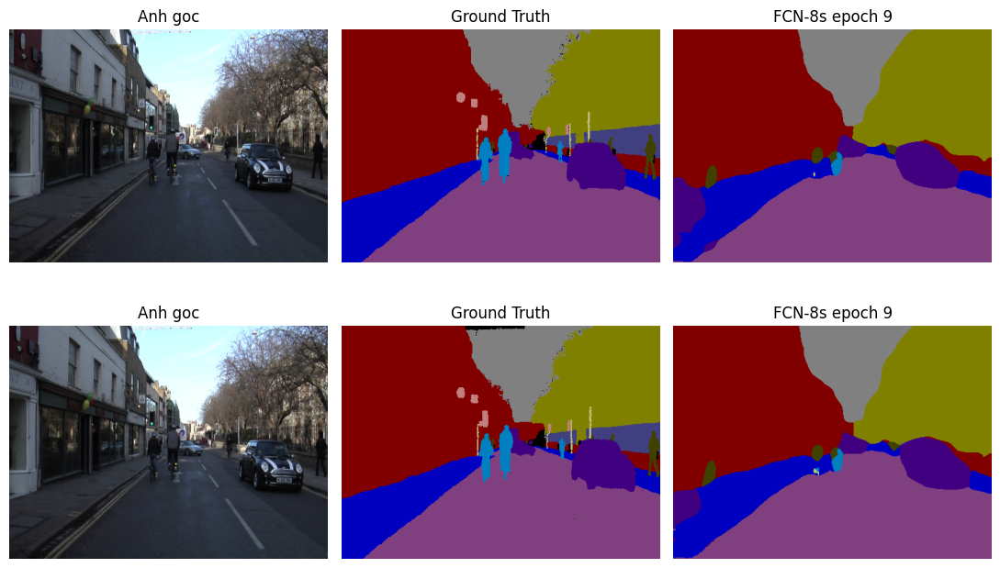

FCN-8s | Epoch 10/20 | train_loss=0.4174 | val_loss=0.3598 | PA=0.8902 | mIoU=0.4955


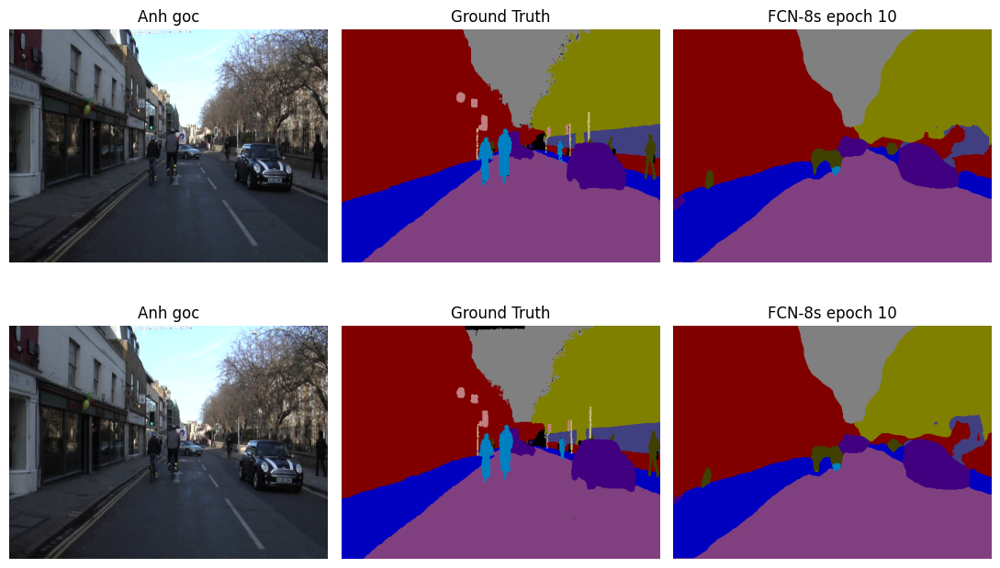

FCN-8s | Epoch 11/20 | train_loss=0.3710 | val_loss=0.3276 | PA=0.8983 | mIoU=0.5261


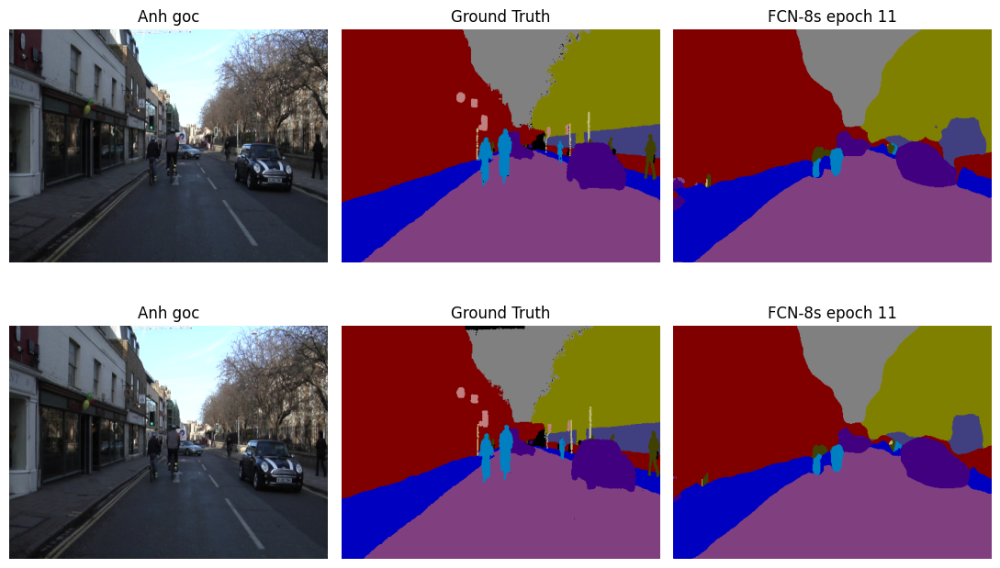

FCN-8s | Epoch 12/20 | train_loss=0.3586 | val_loss=0.3656 | PA=0.8869 | mIoU=0.5168


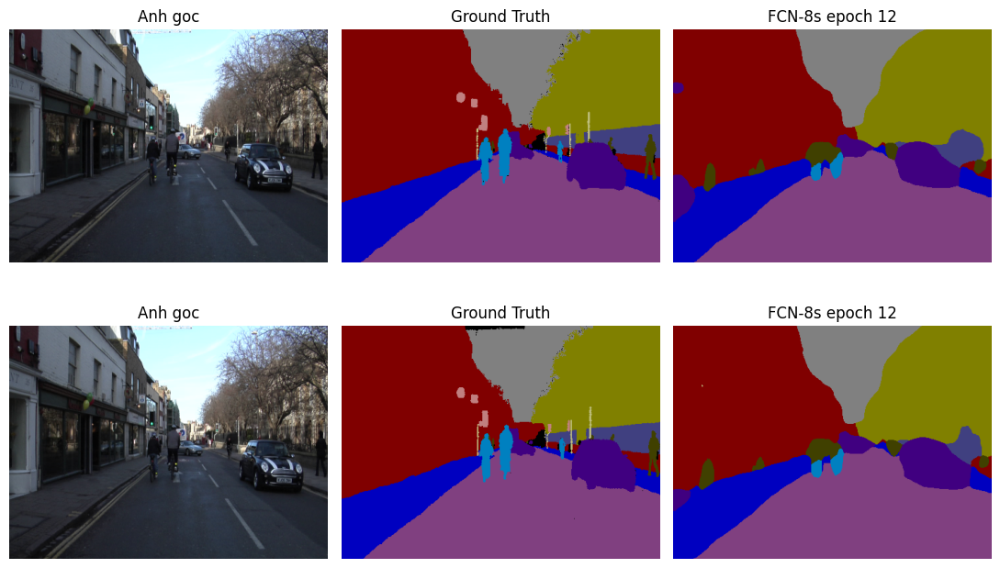

FCN-8s | Epoch 13/20 | train_loss=0.3403 | val_loss=0.3401 | PA=0.8914 | mIoU=0.4996


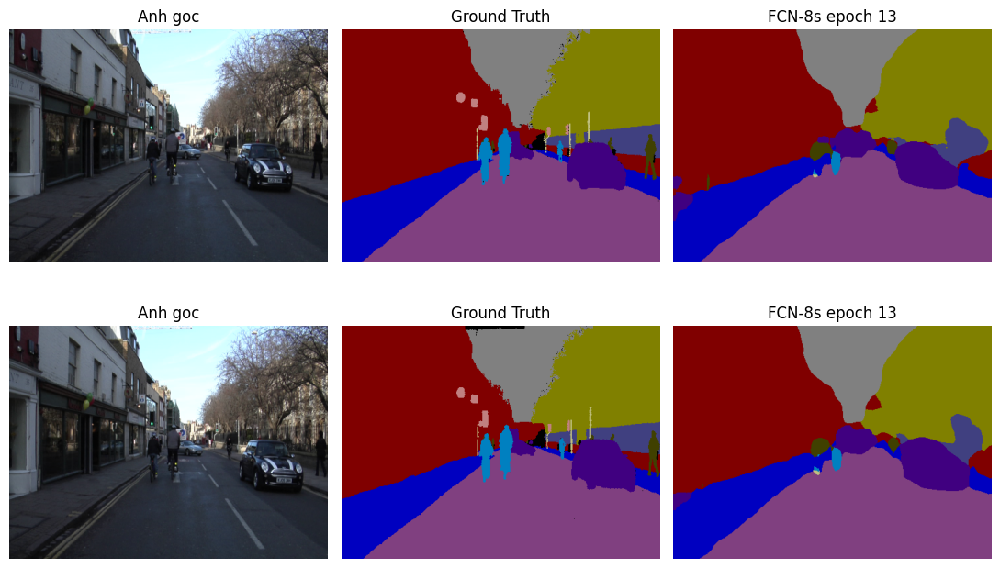

FCN-8s | Epoch 14/20 | train_loss=0.3232 | val_loss=0.3265 | PA=0.8957 | mIoU=0.5403


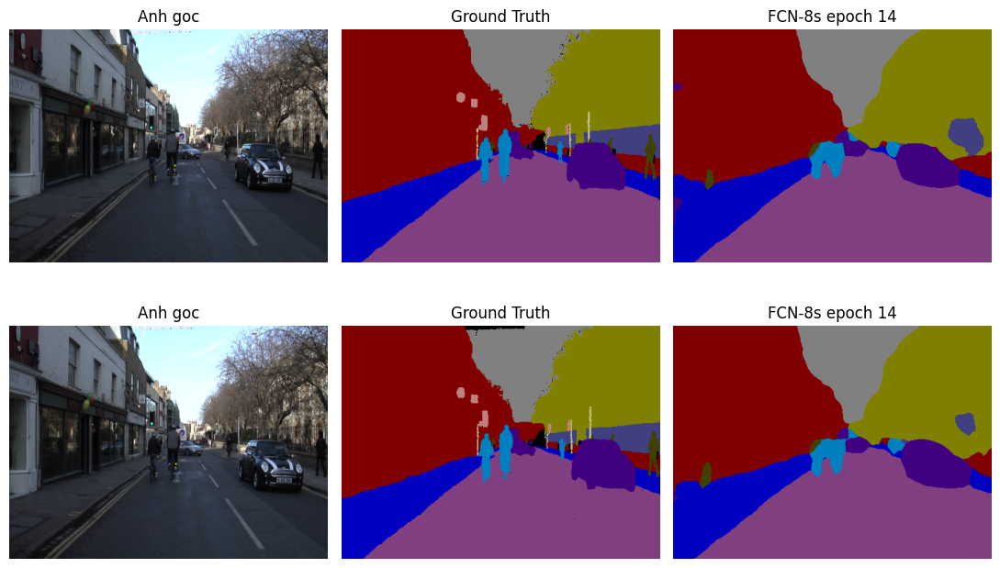

FCN-8s | Epoch 15/20 | train_loss=0.3152 | val_loss=0.3077 | PA=0.9010 | mIoU=0.5544


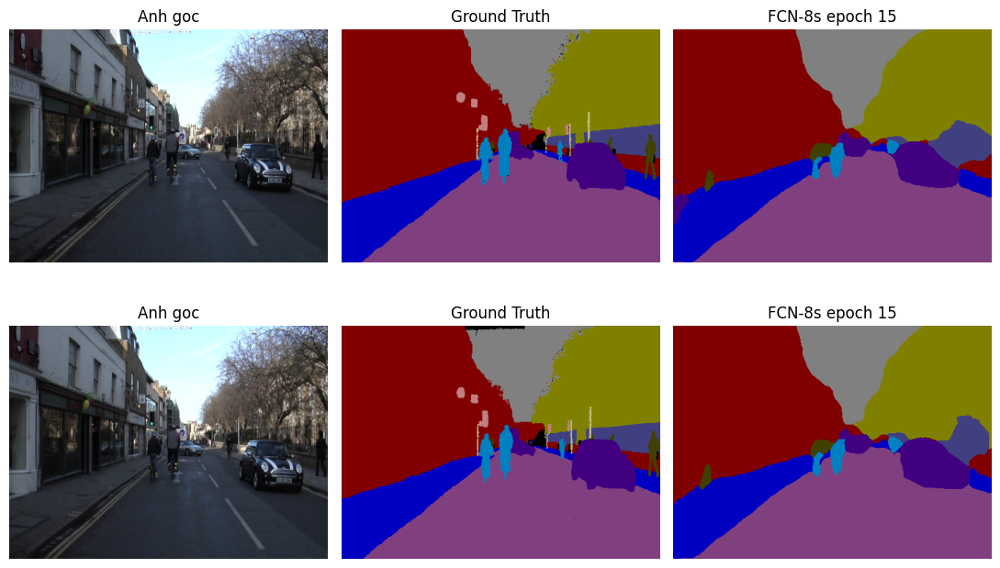

FCN-8s | Epoch 16/20 | train_loss=0.3009 | val_loss=0.3492 | PA=0.8885 | mIoU=0.5457


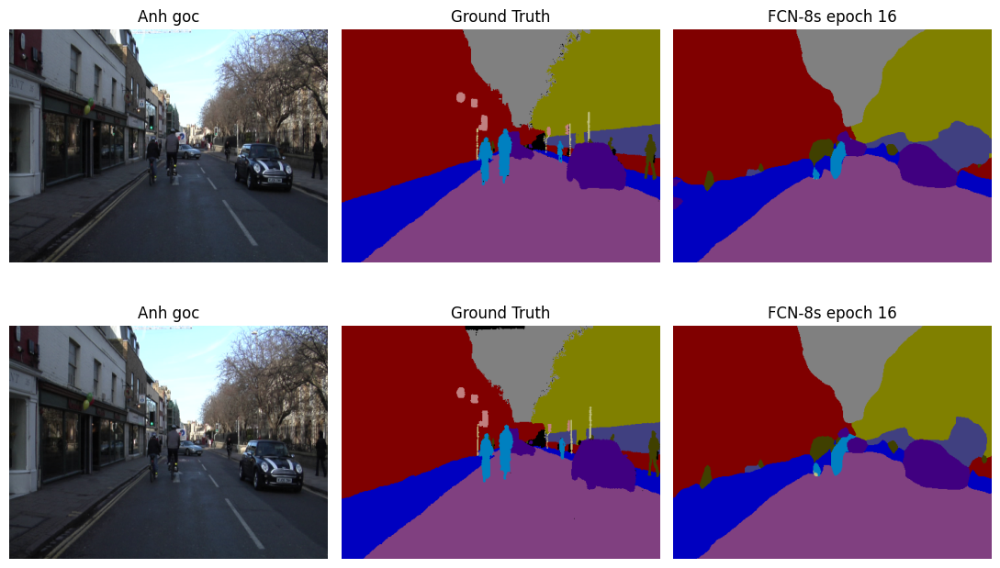

FCN-8s | Epoch 17/20 | train_loss=0.2893 | val_loss=0.3007 | PA=0.9051 | mIoU=0.5527


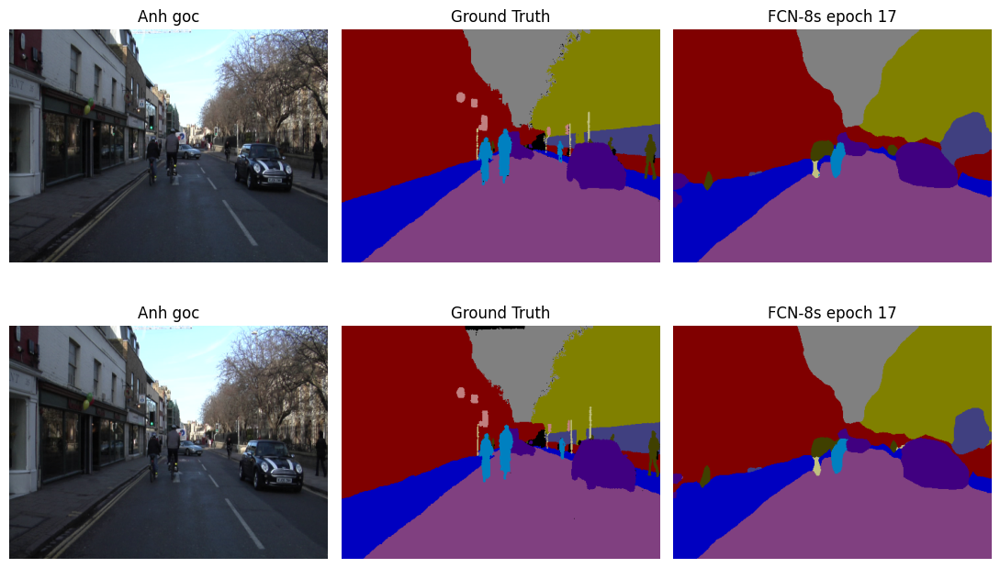

FCN-8s | Epoch 18/20 | train_loss=0.2867 | val_loss=0.3076 | PA=0.9024 | mIoU=0.5884


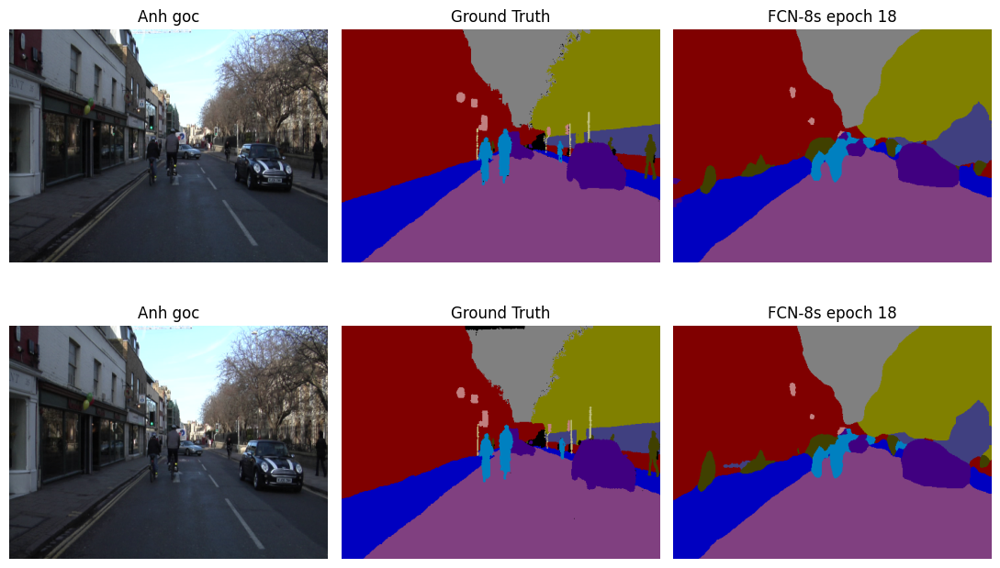

FCN-8s | Epoch 19/20 | train_loss=0.2663 | val_loss=0.3263 | PA=0.8977 | mIoU=0.5257


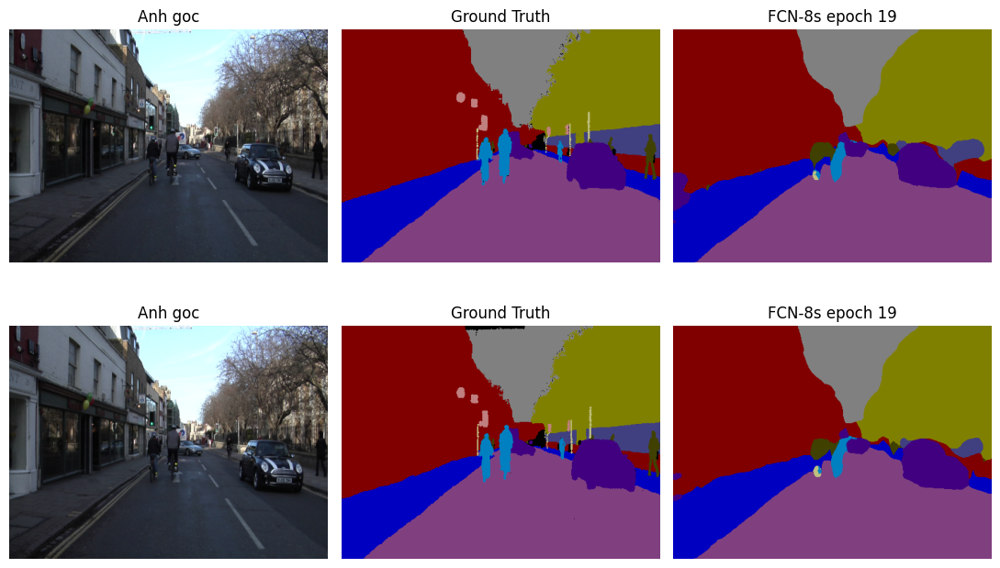

FCN-8s | Epoch 20/20 | train_loss=0.2473 | val_loss=0.3030 | PA=0.9023 | mIoU=0.5561


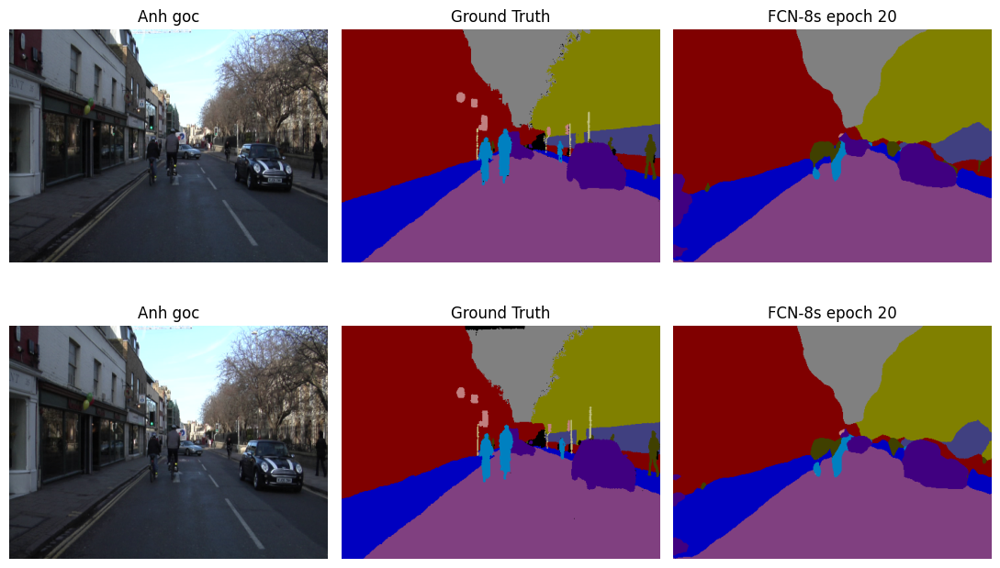

In [47]:
# Cell 14 - Chay train khi Run All
history32 = train_model(model32, "FCN-32s", train_loader, val_loader, NUM_CLASSES, epochs=EPOCHS)
history8 = train_model(model8, "FCN-8s", train_loader, val_loader, NUM_CLASSES, epochs=EPOCHS)

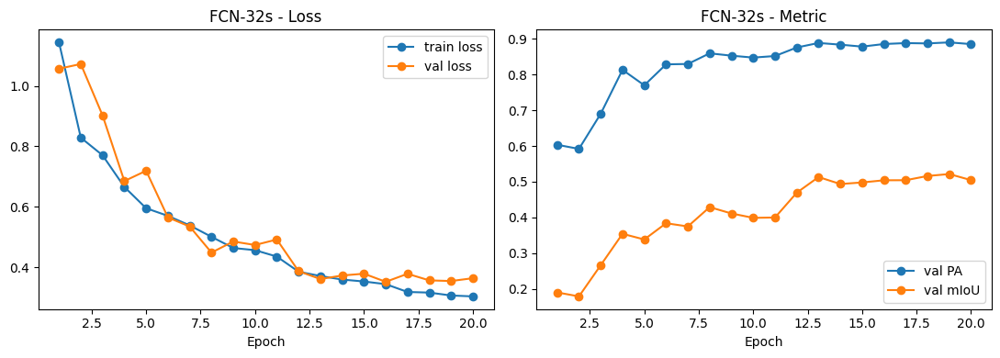

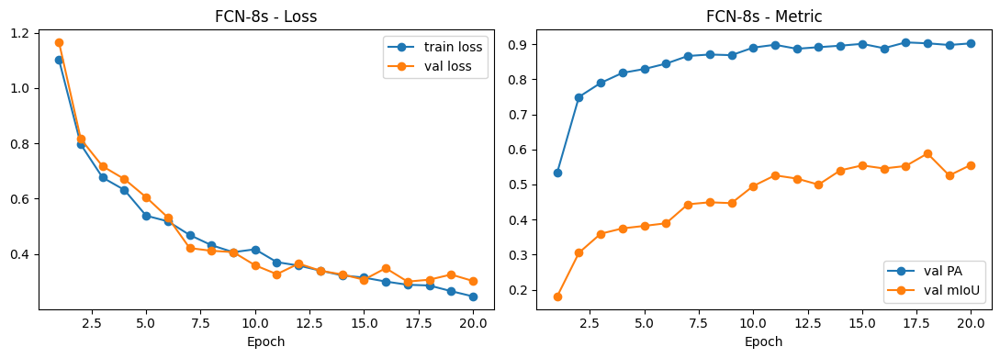

In [48]:
# Cell 15 - Ve loss va metric sau train
def ve_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(epochs, history["train_loss"], marker="o", label="train loss")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="val loss")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(epochs, history["val_pixel_acc"], marker="o", label="val PA")
    axes[1].plot(epochs, history["val_miou"], marker="o", label="val mIoU")
    axes[1].set_title(f"{title} - Metric")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    display(fig)
    plt.close(fig)

ve_history(history32, "FCN-32s")
ve_history(history8, "FCN-8s")

In [49]:
# Cell 16 - Danh gia test va lap bang so sanh
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
metrics32 = evaluate(model32.to(DEVICE), test_loader, criterion, NUM_CLASSES)
metrics8 = evaluate(model8.to(DEVICE), test_loader, criterion, NUM_CLASSES)

bang_ket_qua = [
    {"model": "FCN-32s", "test_loss": metrics32["loss"], "PA": metrics32["pixel_acc"], "mIoU": metrics32["miou"]},
    {"model": "FCN-8s", "test_loss": metrics8["loss"], "PA": metrics8["pixel_acc"], "mIoU": metrics8["miou"]},
]

bang_ket_qua

[{'model': 'FCN-32s',
  'test_loss': 0.5899304180953636,
  'PA': 0.8251792192459106,
  'mIoU': 0.40898749232292175},
 {'model': 'FCN-8s',
  'test_loss': 0.5240425317200468,
  'PA': 0.8431712985038757,
  'mIoU': 0.4380578100681305}]

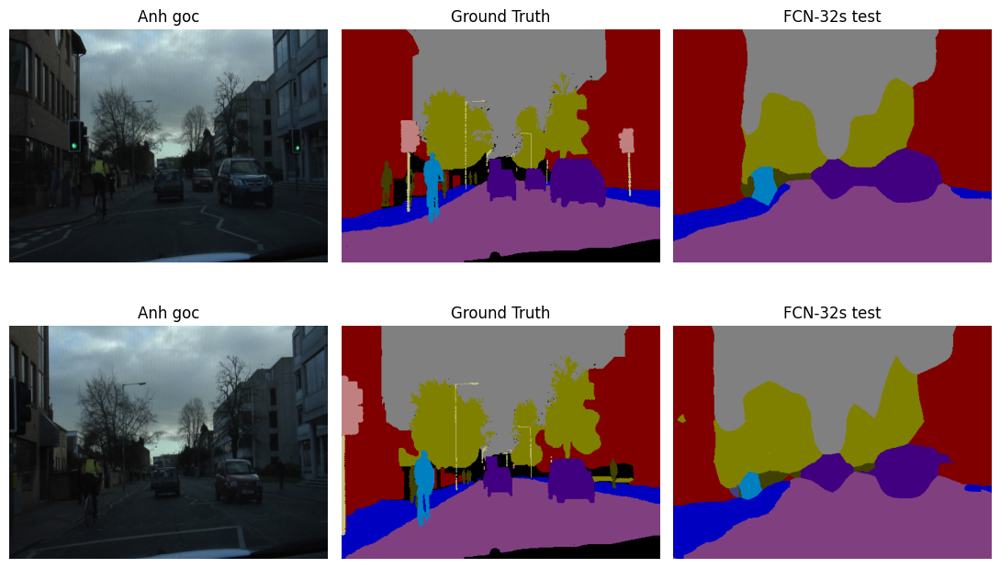

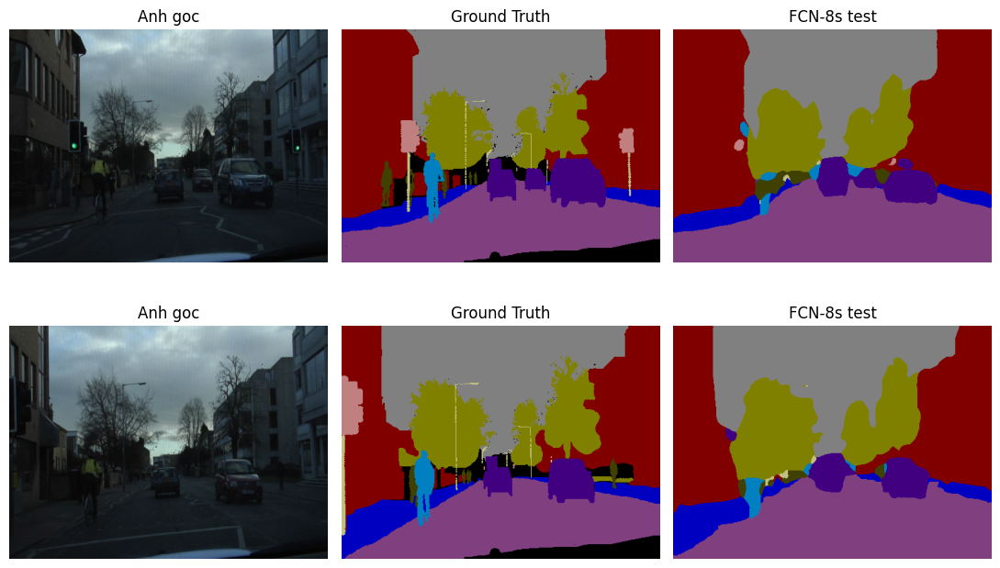

In [50]:
# Cell 17 - Show ket qua cuoi cung tren test set
show_prediction(model32, test_loader, title="FCN-32s test", count=SHOW_COUNT)
show_prediction(model8, test_loader, title="FCN-8s test", count=SHOW_COUNT)